# Recursive Right-Tailed Unit-Root Statistics

The regression tests whether a level follows a unit root or grows at an explosive rate over a chosen window:

$$
\Delta y_t
=\alpha+\beta y_{t-1}
+\sum_{j=1}^{k}\psi_j\Delta y_{t-j}
+\varepsilon_t,
\qquad
H_0:\beta=0,
\qquad
H_1:\beta>0.
$$

Here, $y_t$ is the logged level at time $t$; $\Delta y_t=y_t-y_{t-1}$ is its first difference. $\alpha$ is an intercept; $\beta$ is the coefficient tested in the right tail; $k$ is the number of lagged differences. $\psi_j$ is the coefficient on lag $j$; $\varepsilon_t$ is the remaining disturbance; $H_0$ and $H_1$ are the null and explosive alternatives.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("12_structural_breaks");
using CSV, Printf, TOML
using RiskLabAI.Features: compute_beta,get_bsadf_sequence,get_bubble_episodes,get_expanding_window_adf,get_gsadf_statistic,get_sadf_sequence,pelt_change_points,prepare_data,psy_minimum_window,simulate_psy_critical_values,volatility_robust_sadf
data_path = dataset_path("fred_nasdaq")
@assert isfile(data_path)
raw = CSV.read(data_path,DataFrame;missingstring=["","."])
raw.observation_date = Date.(raw.observation_date)
daily_price = sort(dropmissing(raw,:NASDAQCOM),:observation_date)
monthly_price = combine(groupby(transform(daily_price,:observation_date=>(dates->lastdayofmonth.(dates))=>:month),:month;sort=true),:NASDAQCOM=>last=>:price)
monthly_time = DateTime.(monthly_price.month)
log_price = log.(monthly_price.price)
monthly_return = diff(log_price)
return_time = monthly_time[2:end]
date_ticks = DateTime.(Date(1995):Year(5):Date(2025))
year_ticks = (Dates.value.(date_ticks),Dates.format.(date_ticks,dateformat"yyyy"))
replay_directory = joinpath("..","data","chapter12_random_inputs")
replay_manifest = TOML.parsefile(joinpath(replay_directory,"inputs.toml"))

function replay_matrix(name)
    filename = name*".csv"
    path = joinpath(replay_directory,filename)
    record = replay_manifest["files"][filename]
    values = Matrix(CSV.read(path,DataFrame))
    @assert size(values) == (record["rows"],record["columns"])
    return values
end

function save_sequence(name,sequence;times=monthly_time)
    save_data(DataFrame(position=sequence.index,time=times[sequence.index],statistic=sequence.values),paths,name)
    return nothing
end


save_sequence (generic function with 1 method)

## Public NASDAQ Composite Levels

Row,Field,Value
,String,String
1,Provider,Federal Reserve Bank of St. Louis
2,Series,"NASDAQ Composite, NASDAQCOM"
3,Frequency used,Month end
4,First month,1994-01-31
5,Last month,2025-12-31
6,Daily rows,"8,348"
7,Missing daily values,293
8,Monthly observations,384
9,Retrieved,2026-09-26


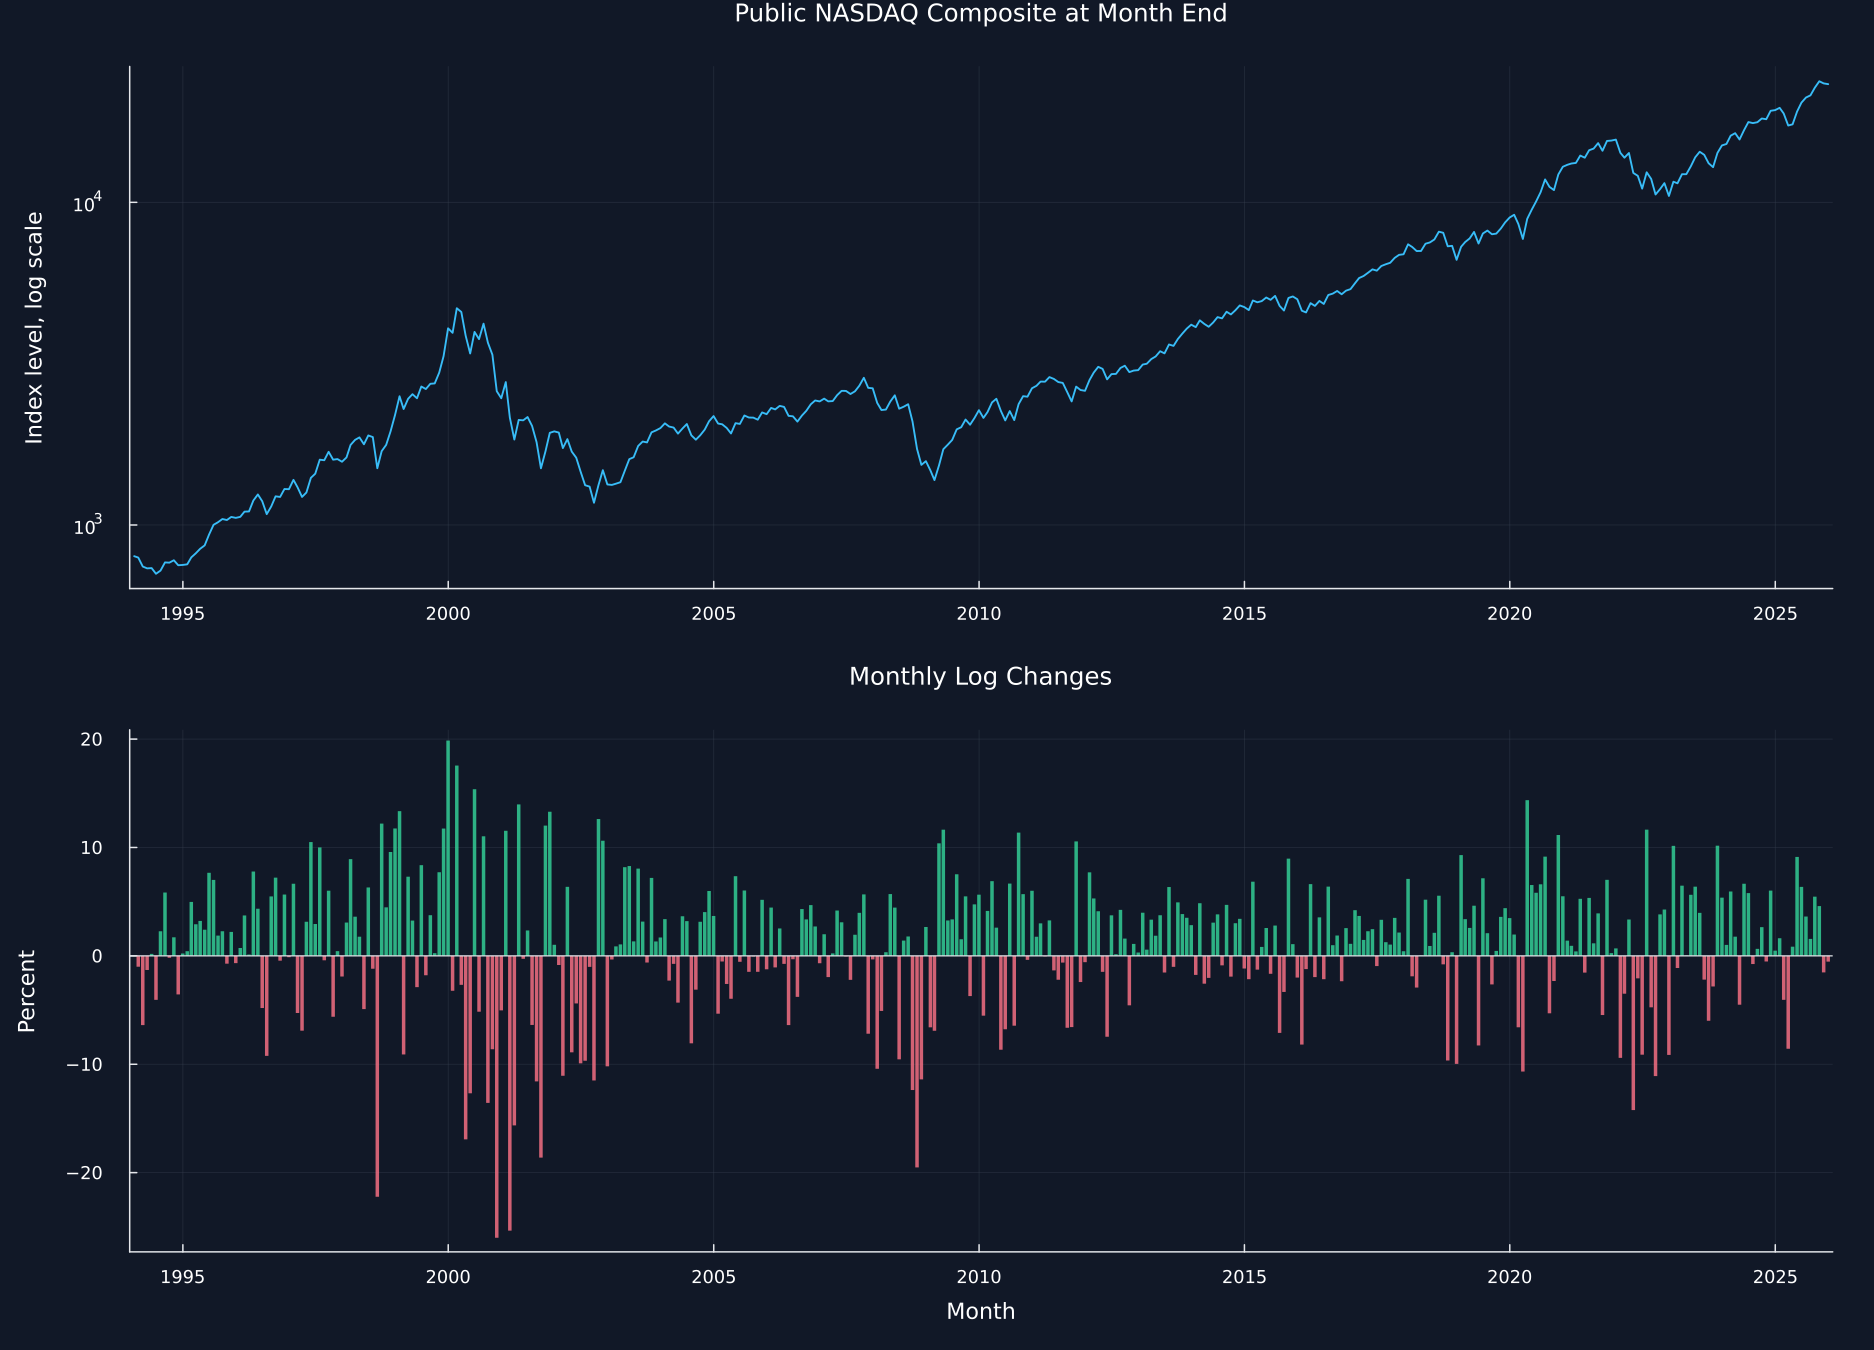

In [2]:
data_provenance = DataFrame("Field"=>["Provider","Series","Frequency used","First month","Last month","Daily rows","Missing daily values","Monthly observations","Retrieved"],"Value"=>["Federal Reserve Bank of St. Louis","NASDAQ Composite, NASDAQCOM","Month end",string(first(monthly_price.month)),string(last(monthly_price.month)),"8,348",string(count(ismissing,raw.NASDAQCOM)),string(nrow(monthly_price)),"2026-09-26"])
save_table(data_provenance,paths,"data_provenance";caption="Fixed public observations used in Chapter 11.",label="tab:chapter11-data-provenance")
p1 = plot(monthly_time,monthly_price.price;yscale=:log10,color=palette.cyan,linewidth=1.25,label=false,title="Public NASDAQ Composite at Month End",ylabel="Index level, log scale",xticks=year_ticks)
p2 = bar(return_time,100monthly_return;bar_width=Dates.value(Millisecond(Day(24))),color=ifelse.(monthly_return.>=0,palette.green,palette.rose),alpha=.82,linealpha=0,label=false,title="Monthly Log Changes",xlabel="Month",ylabel="Percent",xticks=year_ticks)
hline!(p2,[0];color=palette.text,linewidth=.8,label=false)
plot!(p2;ylims=(105minimum(monthly_return),105maximum(monthly_return)))
save_figure(plot(p1,p2;layout=(2,1),size=(1250,900),left_margin=6Plots.mm,xlims=(Dates.value(first(monthly_time)-Day(31)),Dates.value(last(monthly_time)+Day(31)))),paths,"public_nasdaq_monthly")
save_data(DataFrame(time=monthly_time,price=monthly_price.price,log_price=log_price),paths,"monthly_nasdaq");
save_data(DataFrame(time=return_time,log_return=monthly_return),paths,"monthly_log_returns");


## The Right-Tailed Statistic

Ordinary least squares estimates the regression, and the ADF value measures the lagged-level estimate in standard-error units:

$$
\widehat\theta=(X^{\mathsf T}X)^{-1}X^{\mathsf T}d,
\qquad
\widehat V(\widehat\theta)
=\widehat\sigma_{\varepsilon}^{2}(X^{\mathsf T}X)^{-1},
\qquad
\operatorname{ADF}=\frac{\widehat\beta}{\sqrt{\widehat V(\widehat\theta)_{\beta\beta}}}.
$$

Here, $X$ is the regression matrix; $d$ is the vector of first differences; $\widehat\theta$ contains all estimated coefficients. $\widehat\beta$ is the estimated lagged-level coefficient; $\widehat\sigma_{\varepsilon}^{2}$ is residual variance; $\widehat V$ is the coefficient covariance matrix. $\mathsf T$ denotes transpose; $\widehat V(\widehat\theta)_{\beta\beta}$ is the variance assigned to $\widehat\beta$; $\operatorname{ADF}$ is the right-tailed test statistic.

In [3]:
dependent,regressors,regression_index = prepare_data(log_price,"c",0)
beta_mean,beta_variance = compute_beta(dependent,regressors)
manual_beta = (transpose(regressors)*regressors)\(transpose(regressors)*dependent)
standard_errors = sqrt.(diag(beta_variance))
coefficient_names = ["level_l1","constant"]
regression_audit = DataFrame("Term"=>coefficient_names,"Estimate"=>beta_mean,"Standard error"=>standard_errors,"Statistic"=>beta_mean./standard_errors,"Independent estimate"=>manual_beta,"Absolute difference"=>abs.(beta_mean.-manual_beta))
save_table(regression_audit,paths,"adf_regression_audit";caption="Full-sample ADF regression and an independent coefficient check.",label="tab:chapter11-adf-regression-audit")
save_data(DataFrame(position=regression_index,dependent=dependent,level_l1=regressors[:,1],constant=regressors[:,2]),paths,"adf_regression_design");
save_data(DataFrame(beta_variance,[:level_l1,:constant]),paths,"adf_coefficient_covariance");


Row,Term,Estimate,Standard error,Statistic,Independent estimate,Absolute difference
,String,Float64,Float64,Float64,Float64,Float64
1,level_l1,-0.000158675,0.00373607,-0.042471,-0.000158675,1.19804e-17
2,constant,0.0100886,0.0306268,0.329402,0.0100886,1.07553e-16


## Expanding Windows

The minimum window grows with the sample, and SADF keeps the largest right-tailed statistic from windows anchored at the first observation:

$$
r_0=0.01+\frac{1.8}{\sqrt{T}},
\qquad
n_0=\max\!\left\{3,\operatorname{round}(r_0T)\right\},
\qquad
\operatorname{SADF}(r_0)=\sup_{r_2\in[r_0,1]}\operatorname{ADF}_{0}^{r_2}.
$$

Here, $T$ is the total number of observations; $r_0$ is the minimum window as a sample fraction; $n_0$ is its observation count. $r_2$ is a window endpoint as a sample fraction; $\operatorname{ADF}_{0}^{r_2}$ uses observations from the sample origin through $r_2.$ $\sup$ denotes the largest value over admissible endpoints; $\operatorname{SADF}(r_0)$ is that largest origin-anchored statistic.

Row,Quantity,Value
,String,String
1,Monthly observations,384
2,Minimum window,39
3,First valid endpoint,1997-04-30
4,Final ADF,-0.042471
5,Largest ADF,1.817969
6,Endpoint of largest ADF,2000-02-29
7,Positive-statistic share,0.113043


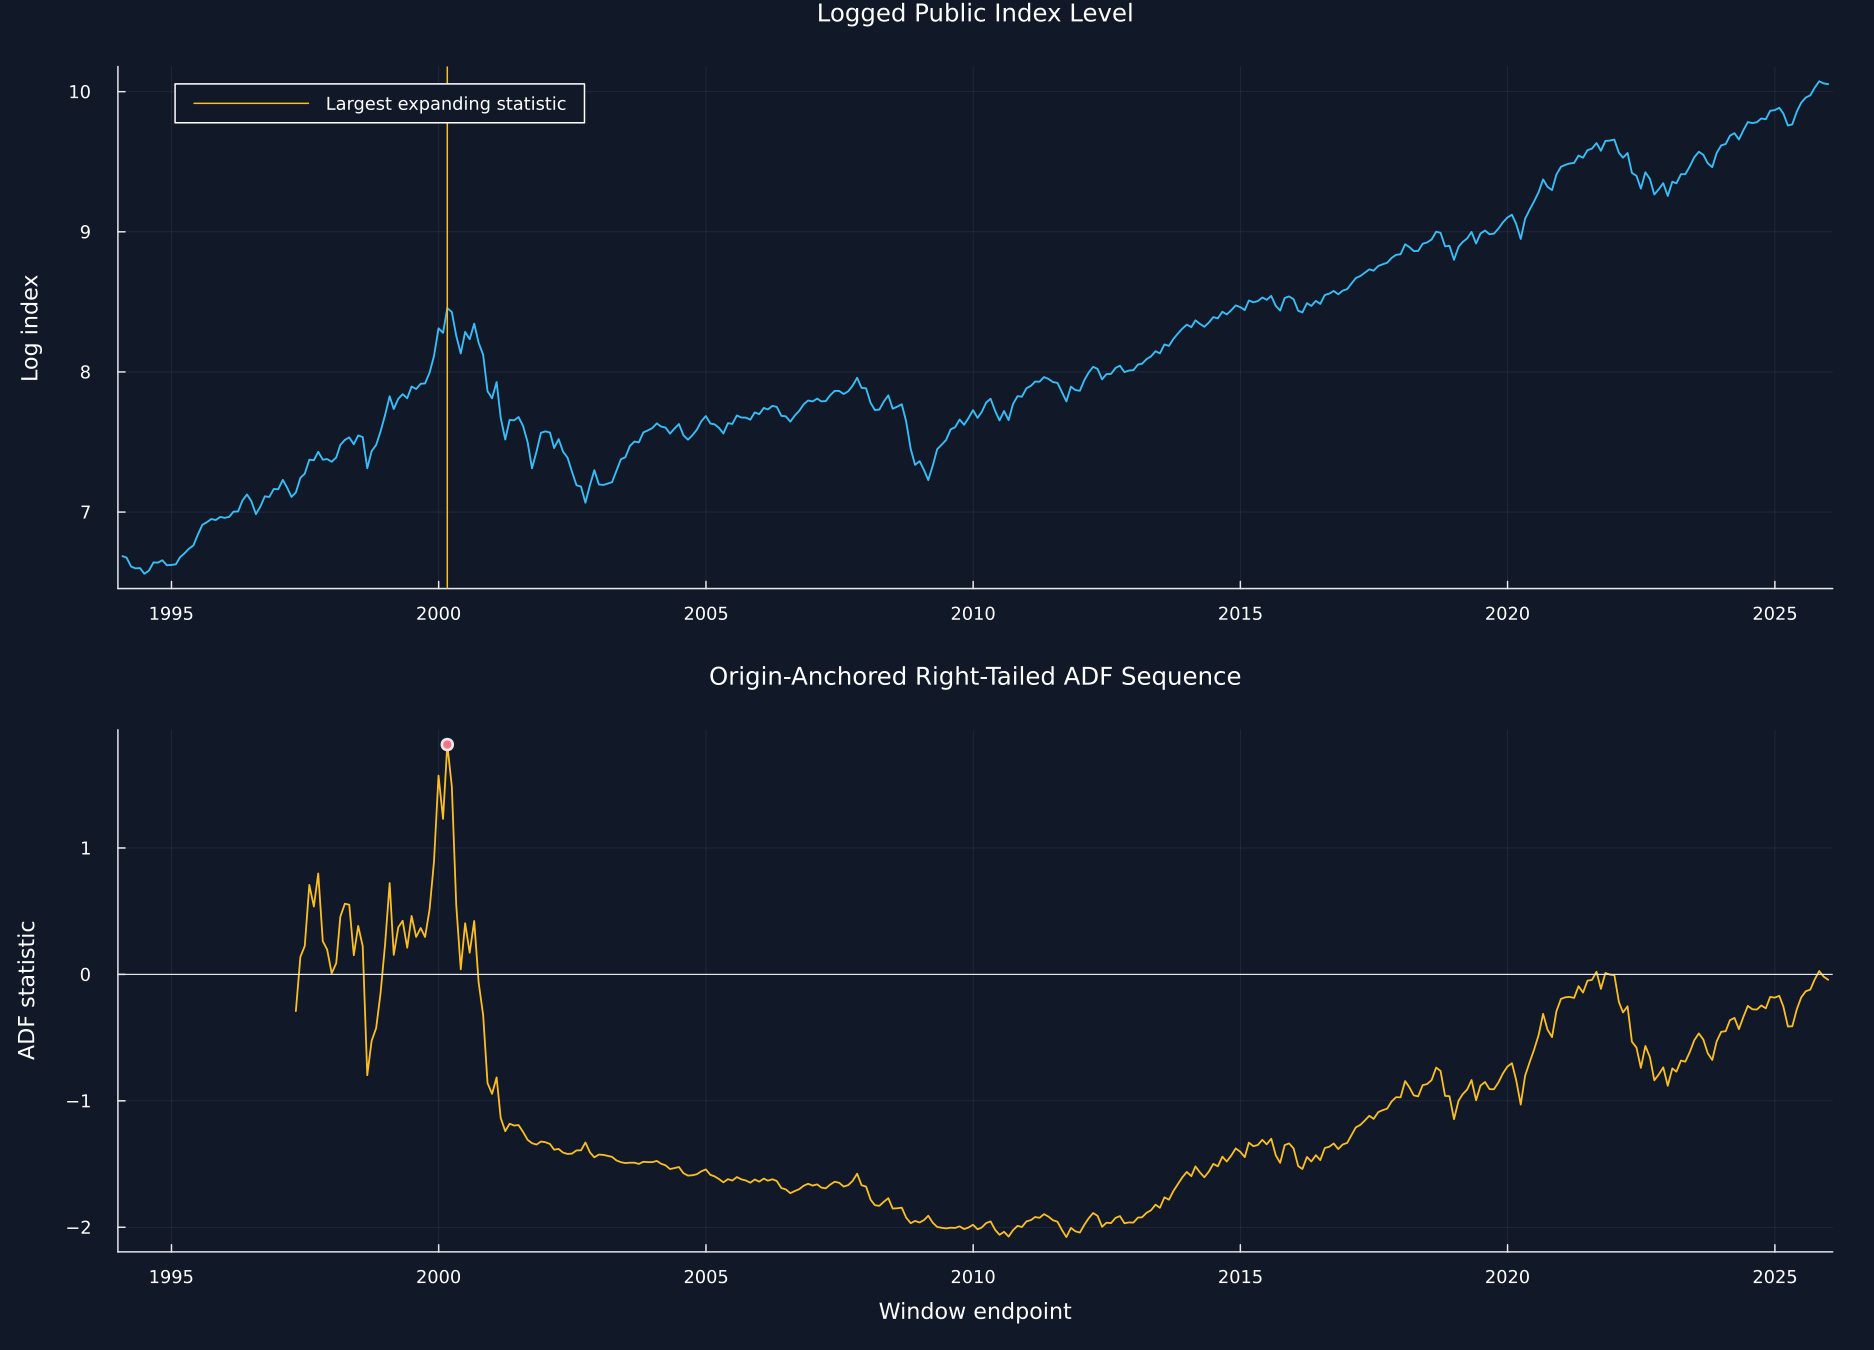

In [4]:
sample_length = length(log_price)
min_window = psy_minimum_window(sample_length)
expanding_adf = get_expanding_window_adf(log_price,min_window,"c",0)
sadf_sequence = get_sadf_sequence(log_price,min_window,"c",0)
maximum_position = sadf_sequence.index[argmax(sadf_sequence.values)]
maximum_date = monthly_time[maximum_position]
expanding_summary = DataFrame("Quantity"=>["Monthly observations","Minimum window","First valid endpoint","Final ADF","Largest ADF","Endpoint of largest ADF","Positive-statistic share"],"Value"=>[string(sample_length),string(min_window),string(Date(monthly_time[first(sadf_sequence.index)])),@sprintf("%.6f",last(sadf_sequence.values)),@sprintf("%.6f",maximum(sadf_sequence.values)),string(Date(maximum_date)),@sprintf("%.6f",mean(sadf_sequence.values.>0))])
save_table(expanding_summary,paths,"expanding_adf_summary";caption="Summary of the origin-anchored expanding ADF sequence.",label="tab:chapter11-expanding-adf-summary")
p1 = plot(monthly_time,log_price;color=palette.cyan,linewidth=1.25,label=false,title="Logged Public Index Level",ylabel="Log index",xticks=year_ticks,legend=:topleft)
vline!(p1,[Dates.value(maximum_date)];color=palette.amber,linewidth=1,label="Largest expanding statistic")
p2 = plot(monthly_time[sadf_sequence.index],sadf_sequence.values;color=palette.amber,linewidth=1.2,label=false,title="Origin-Anchored Right-Tailed ADF Sequence",xlabel="Window endpoint",ylabel="ADF statistic",xticks=year_ticks)
hline!(p2,[0];color=palette.text,linewidth=.8,label=false)
scatter!(p2,[Dates.value(maximum_date)],[maximum(sadf_sequence.values)];color=palette.rose,markersize=4,label=false)
save_figure(plot(p1,p2;layout=(2,1),size=(1250,900),left_margin=6Plots.mm,xlims=(Dates.value(first(monthly_time)-Day(31)),Dates.value(last(monthly_time)+Day(31)))),paths,"expanding_adf_sequence")
save_data(DataFrame(position=sadf_sequence.index,time=monthly_time[sadf_sequence.index],sadf=sadf_sequence.values,expanding=expanding_adf.statistics),paths,"expanding_adf_sequence");


## Tests

In [5]:
@assert size(raw)==(8348,2)
@assert count(ismissing,raw.NASDAQCOM)==293
@assert first(daily_price.observation_date)==Date(1994,1,3)
@assert last(daily_price.observation_date)==Date(2025,12,31)
@assert nrow(monthly_price)==384
@assert first(monthly_price.month)==Date(1994,1,31)
@assert last(monthly_price.month)==Date(2025,12,31)
@assert all(monthly_price.price.>0)
@assert issorted(monthly_price.month)
@assert allunique(monthly_price.month)
@assert length(monthly_return)==383
@assert min_window==39
@assert size(reshape(dependent,:,1))==(383,1)
@assert size(regressors)==(383,2)
@assert coefficient_names==["level_l1","constant"]
@assert isapprox(beta_mean,manual_beta;atol=1e-12,rtol=0)
@assert all(isfinite,beta_variance)
@assert all(diag(beta_variance).>0)
@assert length(expanding_adf.statistics)==length(sadf_sequence.values)
@assert expanding_adf.index==sadf_sequence.index
@assert all(isapprox.(expanding_adf.statistics,sadf_sequence.values;atol=1e-9,rtol=0))
@assert isapprox(maximum(sadf_sequence.values),1.8179690572971872;atol=1e-10)
@assert maximum_date==DateTime(2000,2,29)
@assert isfile(joinpath(paths.figures,"public_nasdaq_monthly.pdf"))
@assert isfile(joinpath(paths.figures,"expanding_adf_sequence.pdf"))
@assert isfile(joinpath(paths.tables,"data_provenance.tex"))
@assert isfile(joinpath(paths.tables,"adf_regression_audit.tex"))
@assert isfile(joinpath(paths.tables,"expanding_adf_summary.tex"))
